In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks, butter, filtfilt
from scipy.interpolate import interp1d
from joblib import Parallel, delayed
import os, warnings
warnings.filterwarnings('ignore')

In [28]:
# ---- Physical constants ----
gamma = 1.41
R     = 287       # J/(kg·K)
cp    = 1050      # J/(kg·K)
cv    = 744       # J/(kg·K)

# ---- Pressures (Pa) ----
P_in  = 6e5
P_out = 5.45e5

# ---- Temperature (K) ----
T_in = 300.0
T0   = T_in

# ---- Resonator geometry ----
A_neck  = 2.85e-4  # m²
L_neck  = 0.15     # m
m_gas   = 0.0015   # kg
V0_cv   = 5.91e-5  # m³
V0_pass = 3.93e-4  # m³

# ---- Damping ----
b_gas = 0.01

# ---- Reed parameters (zeta-independent base values) ----
dP      = P_in - P_out        # pressure difference (Pa)
m_max   = 0.001               # kg/s  (inlet reed max flow)
m_max_out = 0.001 * 1         # kg/s  (outlet reed max flow)
# dP_max is computed per-run as  dP / (2 * zeta)

print(f"P_in  = {P_in/1e5:.3f} bar,  P_out = {P_out/1e5:.3f} bar")
print(f"dP    = {dP:.1f} Pa")
print(f"m_max = {m_max:.4f} kg/s,  m_max_out = {m_max_out:.4f} kg/s")

P_in  = 6.000 bar,  P_out = 5.450 bar
dP    = 55000.0 Pa
m_max = 0.0010 kg/s,  m_max_out = 0.0010 kg/s


In [29]:
def reed_flow(dP_val, m_max_val, dP_max_val):
    """Mass flow rate through a reed valve (positive = flow from high to low pressure)."""
    u = dP_val / dP_max_val
    if 0 < dP_val < dP_max_val:
        return m_max_val * (1 - u) * np.sqrt(u)
    elif dP_val <= 0:
        return -m_max_val * (1 - u) * np.sqrt(abs(u))
    else:
        return 0.0

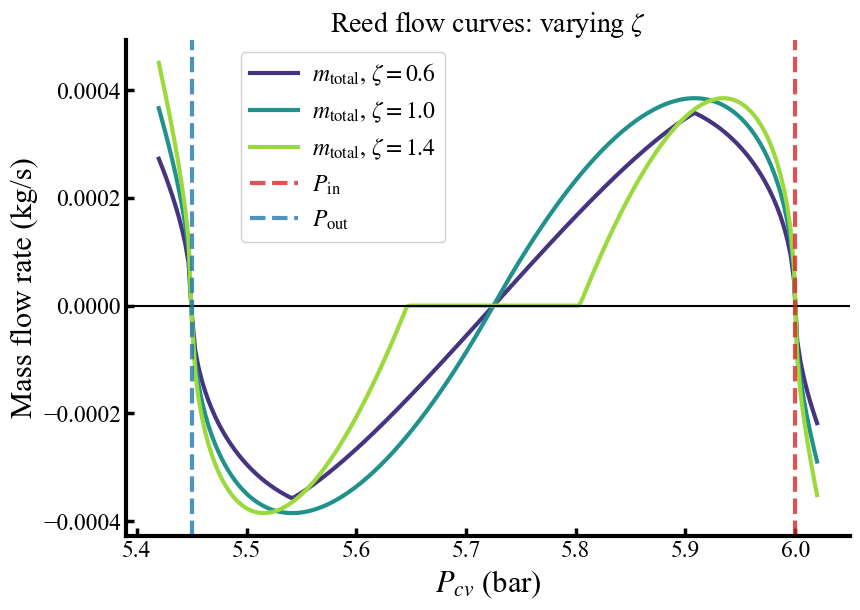

In [30]:
# ---- Reed flow curves for each zeta value ----
# m_max is fixed (0.001); dP_max varies with zeta

P_cv_plot  = np.linspace(5.42e5, 6.02e5, 200)
zeta_plot  = [0.6, 1.0, 1.4]
colors     = plt.cm.viridis(np.linspace(0.15, 0.85, len(zeta_plot)))

with mpl.rc_context({
    "font.family":       "serif",
    "font.serif":        ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset":  "stix",
    "font.size":         20,
    "axes.labelsize":    22,
    "axes.titlesize":    20,
    "xtick.labelsize":   17,
    "ytick.labelsize":   17,
    "legend.fontsize":   17,
    "axes.linewidth":    3.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.major.width": 2.5,
    "ytick.major.width": 2.5,
    "xtick.major.size":  6,
    "ytick.major.size":  6,
}):
    fig, ax = plt.subplots(figsize=(9, 6.5))

    for zeta_v, col in zip(zeta_plot, colors):
        dP_max_v = dP / (2 * zeta_v)
        m_in_v  = np.array([reed_flow(P_in  - p, m_max, dP_max_v) for p in P_cv_plot])
        m_out_v = np.array([-reed_flow(p - P_out, m_max, dP_max_v) for p in P_cv_plot])
        m_tot_v = m_in_v + m_out_v

        ax.plot(P_cv_plot / 1e5, m_tot_v, ls='-', color=col, lw=3.0,
                label=rf"$m_\mathrm{{total}}$, $\zeta={zeta_v}$")

    ax.axhline(0, color='k', lw=1.5, ls='-')
    ax.axvline(P_in  / 1e5, ls='--', lw=3.0, color='tab:red',  alpha=0.8, label=r"$P_\mathrm{in}$")
    ax.axvline(P_out / 1e5, ls='--', lw=3.0, color='tab:blue', alpha=0.8, label=r"$P_\mathrm{out}$")

    ax.set_xlabel(r"$P_{cv}$ (bar)")
    ax.set_ylabel(r"Mass flow rate (kg/s)")
    ax.set_title(r"Reed flow curves: varying $\zeta$")
    ax.legend(ncol=1, framealpha=0.9, handlelength=2.0, handletextpad=0.6,
              loc='upper center', bbox_to_anchor=(0.3, 1.0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.savefig(os.path.join(os.path.dirname(os.path.abspath("__file__")),
                             "zeta_scan_reed_flow.pdf"), dpi=1200, bbox_inches="tight")
    plt.show()

In [32]:
# ---- Envelope analysis ----

def extract_envelopes(signal, peak_distance=None, smooth_cutoff_freq=None, sampling_freq=1.0):
    if not isinstance(signal, np.ndarray):
        signal = np.array(signal)
    indices = np.arange(len(signal))

    if peak_distance is None:
        fft_vals = np.fft.fft(signal)
        freqs    = np.fft.fftfreq(len(signal), 1 / sampling_freq)
        pos_idx  = freqs > 0
        if np.any(pos_idx):
            idx_dom = np.argmax(np.abs(fft_vals[pos_idx]))
            dom_f   = freqs[pos_idx][idx_dom]
            peak_distance = int(sampling_freq / dom_f / 2) if dom_f > 0 else 10
        else:
            peak_distance = 10
    peak_distance = max(1, peak_distance)

    max_peaks, _ = find_peaks( signal, distance=peak_distance)
    min_peaks, _ = find_peaks(-signal, distance=peak_distance)

    if len(max_peaks) > 1:
        upper = interp1d(indices[max_peaks], signal[max_peaks], kind='linear',
                         bounds_error=False,
                         fill_value=(signal[max_peaks[0]], signal[max_peaks[-1]]))(indices)
    else:
        upper = np.full_like(signal, np.nanmax(signal))

    if len(min_peaks) > 1:
        lower = interp1d(indices[min_peaks], signal[min_peaks], kind='linear',
                         bounds_error=False,
                         fill_value=(signal[min_peaks[0]], signal[min_peaks[-1]]))(indices)
    else:
        lower = np.full_like(signal, np.nanmin(signal))

    upper = np.maximum(upper, lower)
    return upper, lower


def envelope_trajectory(P_cv_arr, downsample=5, plot_subsample=100):
    P_ds   = P_cv_arr[::downsample].astype(float)
    idx_ds = np.arange(len(P_ds), dtype=float)
    upper, lower = extract_envelopes(P_ds, sampling_freq=1.0)
    avg = (upper + lower) / 2.0
    amp = np.maximum((upper - lower) / 2.0, 0.0)
    sl  = slice(None, None, plot_subsample)
    return idx_ds[sl], avg[sl], amp[sl]

In [33]:
def simulate_and_trace(
    P0_val, v0_val,
    # --- physics (passed explicitly so joblib workers are stateless) ---
    _P_in, _P_out, _R, _cp, _cv, _T_in, _T0, _gamma,
    _A_neck, _L_neck, _V0_cv, _V0_pass, _m_gas, _b_gas,
    _m_max, _dP_max, _m_max_out, _dP_max_out,
    # --- simulation ---
    t_span=(0.0, 10.0), n_eval=100_000,
    downsample=5, plot_subsample=100,
):
    def _reed(dP_v, m_mx, dP_mx):
        u = dP_v / dP_mx
        if 0 < dP_v < dP_mx:
            return m_mx * (1 - u) * (u ** 0.5)
        elif dP_v <= 0:
            return -m_mx * (1 - u) * (abs(u) ** 0.5)
        return 0.0

    from scipy.signal import find_peaks as _fp
    from scipy.interpolate import interp1d as _i1d

    def _extract(sig):
        sig = np.asarray(sig, dtype=float)
        idx = np.arange(len(sig))
        fv  = np.fft.fft(sig)
        fr  = np.fft.fftfreq(len(sig))
        pos = fr > 0
        pd  = int(1.0 / (fr[pos][np.argmax(np.abs(fv[pos]))] * 2)) if np.any(pos) else 10
        pd  = max(1, pd)
        mxp, _ = _fp( sig, distance=pd)
        mnp, _ = _fp(-sig, distance=pd)
        ue = _i1d(idx[mxp], sig[mxp], kind='linear', bounds_error=False,
                  fill_value=(sig[mxp[0]], sig[mxp[-1]]))(idx) if len(mxp) > 1 else np.full_like(sig, np.nanmax(sig))
        le = _i1d(idx[mnp], sig[mnp], kind='linear', bounds_error=False,
                  fill_value=(sig[mnp[0]], sig[mnp[-1]]))(idx) if len(mnp) > 1 else np.full_like(sig, np.nanmin(sig))
        return np.maximum(ue, le), le

    def _traj(pcv, ds, ps):
        pds  = pcv[::ds].astype(float)
        idxd = np.arange(len(pds), dtype=float)
        u, l = _extract(pds)
        avg  = (u + l) / 2.0
        amp  = np.maximum((u - l) / 2.0, 0.0)
        sl   = slice(None, None, ps)
        return idxd[sl], avg[sl], amp[sl]

    def ode(t, y):
        x, v, M_cv, E_cv = y
        V_cv = _V0_cv + x * _A_neck
        if V_cv <= 0 or M_cv <= 0:
            return [0.0, 0.0, 0.0, 0.0]
        T_cv = E_cv / (_cv * M_cv)
        Pcv  = M_cv * _R * T_cv / V_cv
        V_pp = _V0_pass - x * _A_neck
        P_pp = P0_val * (_V0_pass / V_pp) ** _gamma if V_pp > 0 else P0_val
        dPi  = _P_in - Pcv
        dPo  = Pcv   - _P_out
        mi   = _reed(dPi, _m_max,     _dP_max)
        mo   = _reed(dPo, _m_max_out, _dP_max_out)
        dV   = _A_neck * v
        return [
            v,
            (Pcv - P_pp) * _A_neck / _m_gas - (_b_gas / _m_gas) * v,
            mi - mo,
            -Pcv * dV + mi * _cp * _T_in - mo * _cp * T_cv,
        ]

    # Match Acoustic_Expander_22.ipynb: small displacement perturbation to break equilibrium
    x0 = 0.01 * _L_neck
    M0 = P0_val * _V0_cv / (_R * _T0)
    E0 = _cv * M0 * _T0
    y0 = [x0, float(v0_val), M0, E0]

    try:
        sol = solve_ivp(
            ode, t_span, y0,
            t_eval=np.linspace(t_span[0], t_span[1], int(n_eval)),
            method='RK45', rtol=1e-6, atol=1e-8,
        )
        if not sol.success:
            return P0_val, v0_val, None, None, None
        x, M, E = sol.y[0], sol.y[2], sol.y[3]
        V   = _V0_cv + x * _A_neck
        T   = E / (_cv * M)
        Pcv = M * _R * T / V
        idx, avg, amp = _traj(Pcv, downsample, plot_subsample)
        return P0_val, v0_val, idx, avg, amp
    except Exception:
        return P0_val, v0_val, None, None, None

In [34]:
# ---- Scan configuration ----
zeta_range = [0.6, 0.8, 1.0, 1.2, 1.4]
P0_range   = np.linspace(5.6e5, 5.8e5, 30)   # Pa  (5.60 – 5.80 bar, 30 points)
v0_fixed   = 0.0                              # no initial velocity; x0 perturbation used instead

# Simulation settings
t_end  = 10.0
n_eval = 500_000    # 50 kHz effective rate → ~370 samples/cycle at 135 Hz
ds     = 1          # no downsampling → all 500k samples used for accurate peak detection
ps     = 100

# Base physics bundle (dP_max / dP_max_out are added per-task)
phys_base = dict(
    _P_in=P_in, _P_out=P_out, _R=R, _cp=cp, _cv=cv,
    _T_in=T_in, _T0=T0, _gamma=gamma,
    _A_neck=A_neck, _L_neck=L_neck, _V0_cv=V0_cv, _V0_pass=V0_pass,
    _m_gas=m_gas, _b_gas=b_gas,
    _m_max=m_max, _m_max_out=m_max_out,
)
sim = dict(t_span=(0.0, t_end), n_eval=n_eval, downsample=ds, plot_subsample=ps)

print(f"P0 range  : {P0_range.min()/1e5:.2f} – {P0_range.max()/1e5:.2f} bar  ({len(P0_range)} values)")
print(f"zeta      : {zeta_range}")
print(f"v0 (fixed): {v0_fixed} m/s   (x0 = 0.01·L_neck = {0.01*L_neck*1e3:.2f} mm)")
print(f"n_eval    : {n_eval:,}  (dt ≈ {t_end/n_eval*1e6:.1f} µs)")
print(f"Downsample: {ds}  (envelope uses all {n_eval//ds:,} samples per run)")
print(f"Total runs: {len(P0_range) * len(zeta_range)}")

P0 range  : 5.60 – 5.80 bar  (30 values)
zeta      : [0.6, 0.8, 1.0, 1.2, 1.4]
v0 (fixed): 0.0 m/s   (x0 = 0.01·L_neck = 1.50 mm)
n_eval    : 500,000  (dt ≈ 20.0 µs)
Downsample: 1  (envelope uses all 500,000 samples per run)
Total runs: 150


In [35]:
# ---- Parallel scan over (zeta, P0) ----
for _k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS",
           "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_k, "1")

tasks      = [(z, P0) for z in zeta_range for P0 in P0_range]
task_zetas = [z for z, _ in tasks]

print(f"Launching {len(tasks)} simulations ...")

results_flat = Parallel(n_jobs=-1, verbose=5, backend="loky")(
    delayed(simulate_and_trace)(
        P0, v0_fixed,
        **{**phys_base,
           '_dP_max':     dP / (2 * z),
           '_dP_max_out': dP / (2 * z)},
        **sim
    )
    for z, P0 in tasks
)

# Group results by zeta
results_by_zeta = {z: [] for z in zeta_range}
for z_task, res in zip(task_zetas, results_flat):
    results_by_zeta[z_task].append(res)

good = sum(1 for r in results_flat if r[2] is not None)
print(f"\nDone: {good}/{len(results_flat)} successful runs")

Launching 150 simulations ...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:   23.1s



Done: 150/150 successful runs


[Parallel(n_jobs=-1)]: Done 150 out of 150 | elapsed:  1.1min finished


Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/zeta_scan_zeta=0.6.pdf


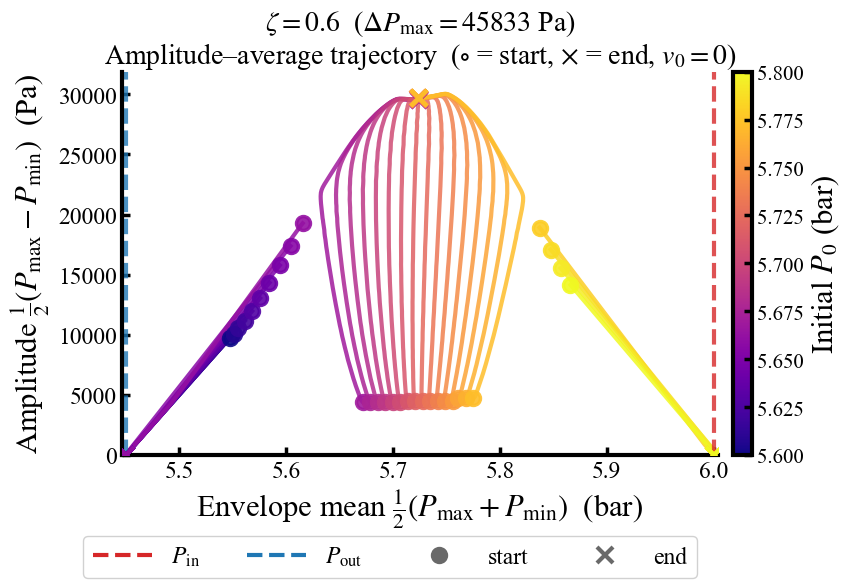

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/zeta_scan_zeta=0.8.pdf


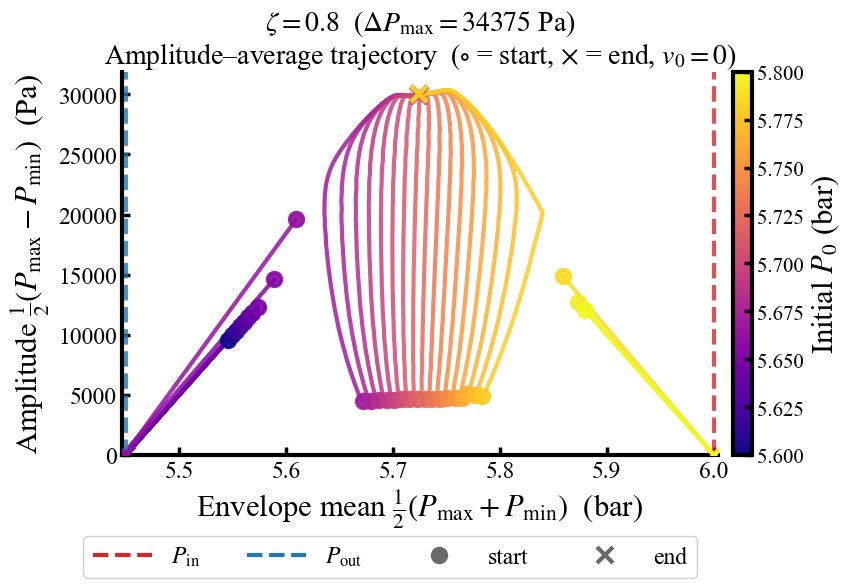

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/zeta_scan_zeta=1.0.pdf


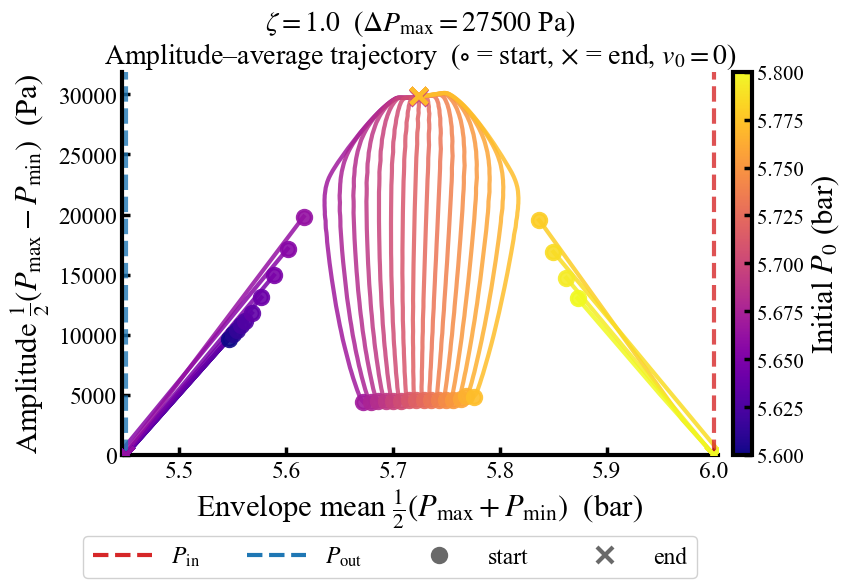

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/zeta_scan_zeta=1.2.pdf


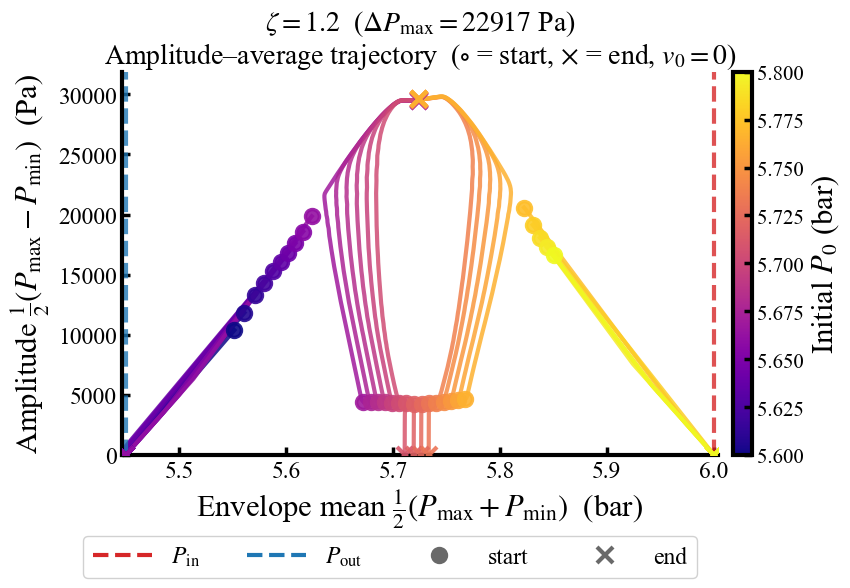

Saved → /Users/a1/Desktop/acoustic project/acoustic_expander/zeta_scan_zeta=1.4.pdf


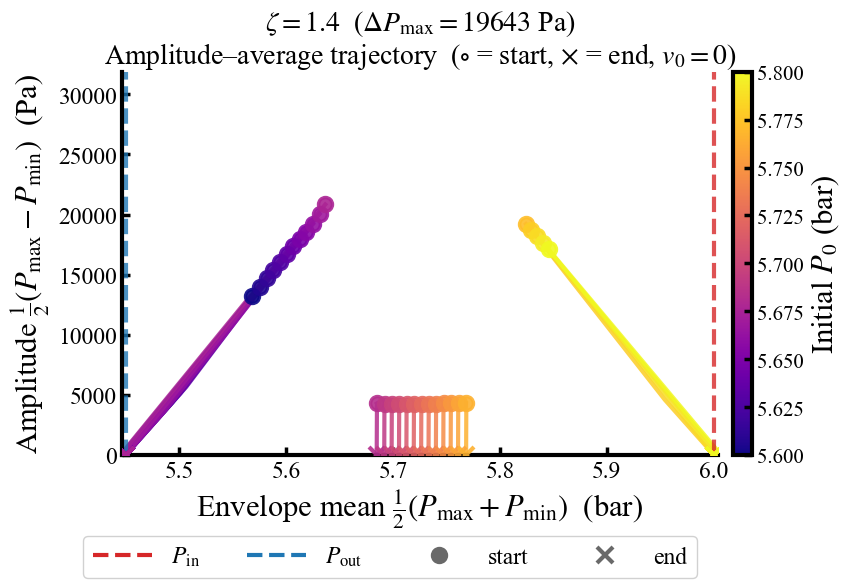

In [36]:
# ---- One separate plot per zeta value ----
# Color = P0 (plasma colormap, consistent scale across all figures)
# × marks the end, ○ marks the start of each trajectory

from matplotlib.lines import Line2D

cmap = plt.get_cmap("plasma")
norm = mcolors.Normalize(vmin=P0_range.min() / 1e5, vmax=P0_range.max() / 1e5)

# Compute global axis limits so all 3 figures are on the same scale
all_avg = [r[3] for rs in results_by_zeta.values() for r in rs if r[3] is not None]
all_amp = [r[4] for rs in results_by_zeta.values() for r in rs if r[4] is not None]
xlim = (np.concatenate(all_avg).min() / 1e5, np.concatenate(all_avg).max() / 1e5)
ylim = (0, np.concatenate(all_amp).max() * 1.05)

rc = {
    "font.family":       "serif",
    "font.serif":        ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset":  "stix",
    "font.size":         20,
    "axes.labelsize":    22,
    "axes.titlesize":    20,
    "xtick.labelsize":   17,
    "ytick.labelsize":   17,
    "legend.fontsize":   17,
    "axes.linewidth":    3.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.major.width": 2.5,
    "ytick.major.width": 2.5,
    "xtick.major.size":  6,
    "ytick.major.size":  6,
}

base = os.path.dirname(os.path.abspath("__file__"))

for zeta_val in zeta_range:
    dP_max_z = dP / (2 * zeta_val)
    runs     = results_by_zeta[zeta_val]

    with mpl.rc_context(rc):
        fig, ax = plt.subplots(figsize=(9, 6.5))

        for (P0_val, v0_val, idx, avg, amp) in runs:
            if idx is None:
                continue
            color = cmap(norm(P0_val / 1e5))
            ax.plot(avg / 1e5, amp, color=color, lw=3.0, alpha=0.85)
            ax.plot(avg[0] / 1e5, amp[0], 'o', color=color,
                    ms=10, zorder=6, mew=2.5, alpha=0.9)
            ax.plot(avg[-1] / 1e5, amp[-1], 'x', color=color,
                    ms=11, zorder=6, mew=3.0, alpha=0.9)

        ax.axvline(P_in  / 1e5, ls="--", lw=3.0, color="tab:red",  alpha=0.8)
        ax.axvline(P_out / 1e5, ls="--", lw=3.0, color="tab:blue", alpha=0.8)

        # Colorbar
        sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, pad=0.02)
        cbar.set_label(r"Initial $P_0$ (bar)")
        cbar.outline.set_linewidth(3.0)
        cbar.ax.tick_params(labelsize=15, width=2.5)

        # Legend below axes
        h_in    = Line2D([0],[0], ls='--', lw=3.0, color='tab:red',  label=r"$P_\mathrm{in}$")
        h_out   = Line2D([0],[0], ls='--', lw=3.0, color='tab:blue', label=r"$P_\mathrm{out}$")
        h_start = Line2D([0],[0], marker='o', color='dimgray', lw=0, ms=10, mew=2.5,
                         label="start")
        h_end   = Line2D([0],[0], marker='x', color='dimgray', lw=0, ms=11, mew=3.0,
                         label="end")
        ax.legend(handles=[h_in, h_out, h_start, h_end],
                  loc='upper center', bbox_to_anchor=(0.45, -0.18),
                  ncol=4, framealpha=0.9, handlelength=2.5, handletextpad=0.8)

        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_xlabel(r"Envelope mean $\frac{1}{2}(P_\mathrm{max}+P_\mathrm{min})$  (bar)")
        ax.set_ylabel(r"Amplitude $\frac{1}{2}(P_\mathrm{max}-P_\mathrm{min})$  (Pa)")
        ax.set_title(
            rf"$\zeta = {zeta_val:.1f}$  ($\Delta P_{{\max}} = {dP_max_z:.0f}$ Pa)"
            "\n" r"Amplitude–average trajectory  ($\circ$ = start, $\times$ = end, $v_0 = 0$)"
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        plt.tight_layout()
        fname = os.path.join(base, f"zeta_scan_zeta={zeta_val:.1f}.pdf")
        plt.savefig(fname, dpi=300, bbox_inches="tight")
        print(f"Saved → {fname}")
        plt.show()